In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score)

In [ ]:
df = pd.read_csv(
"ML_Lab_Multiple_Linear_Regression_House_Prices.csv"
)

print(df.head())

   Area_sqft  Bedrooms  Bathrooms  Age_years  Distance_to_Metro_km  Parking  \
0       1726         2          2          0                  14.1        1   
1       2059         2          1          4                   9.8        1   
2       1460         4          4         15                   8.0        1   
3       1894         4          4         18                  10.0        0   
4       1730         1          1          3                   6.8        1   

   Floor  Balconies  Price_Lakhs  
0     10          3       168.54  
1     10          3       185.35  
2      0          3       183.25  
3      0          0       187.83  
4      1          2       158.35  


In [ ]:
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())

(100, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Area_sqft             100 non-null    int64  
 1   Bedrooms              100 non-null    int64  
 2   Bathrooms             100 non-null    int64  
 3   Age_years             100 non-null    int64  
 4   Distance_to_Metro_km  100 non-null    float64
 5   Parking               100 non-null    int64  
 6   Floor                 100 non-null    int64  
 7   Balconies             100 non-null    int64  
 8   Price_Lakhs           100 non-null    float64
dtypes: float64(2), int64(7)
memory usage: 7.2 KB
None
         Area_sqft    Bedrooms   Bathrooms   Age_years  Distance_to_Metro_km  \
count   100.000000  100.000000  100.000000  100.000000            100.000000   
mean   1572.580000    2.970000    2.780000    9.940000              7.807000   
std     532.161652    1.473366  

In [ ]:
features = [
    'Area_sqft',
    'Bedrooms',
    'Bathrooms',
    'Age_years',
    'Distance_to_Metro_km',
    'Parking',
    'Floor',
    'Balconies'
]
X = df[features]
y = df['Price_Lakhs']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
print("Intercept:", model.intercept_)
for feature, coefficient in zip(
    features,
    model.coef_):
    print(feature, ":", coefficient)

Intercept: 1.540058637031052
Area_sqft : 0.07809045505940766
Bedrooms : 5.94999737471294
Bathrooms : 8.99443079433501
Age_years : -1.1102580882398003
Distance_to_Metro_km : -1.26846307480303
Parking : 11.13057045149967
Floor : 1.1983501761790427
Balconies : 2.6170581819725633


In [ ]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})
print(comparison)

    Actual Price  Predicted Price
0         124.51       124.687037
1         186.08       191.461696
2         152.50       150.750720
3         154.34       171.626647
4         110.04        94.660165
5         137.79       162.789603
6         182.26       177.486600
7         128.19       154.835803
8          82.25        90.286583
9         168.54       179.292958
10        185.02       190.026167
11        125.71       118.550867
12        177.12       183.224096
13        166.09       152.438673
14        212.55       215.143411
15        158.35       157.187688
16        207.30       198.017060
17        176.61       183.729511
18        136.99       147.852328
19        156.87       168.839046


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Absolute Error (MAE): 9.5047
Mean Squared Error (MSE): 140.5759
R-squared (R2) Score: 0.8618


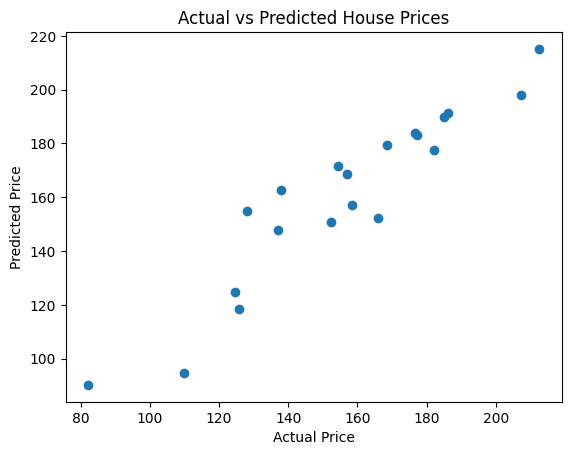

In [ ]:
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(
    "Actual vs Predicted House Prices"
    )
plt.show()

In [ ]:
new_house = [[
    1800,
    3,
    2,
    5,
    3.5,
    1,
    5,
    2
    ]]

predicted_price = model.predict(new_house)
print(
    "Predicted House Price:", predicted_price[0], "Lakhs")

Predicted House Price: 190.30725795010412 Lakhs


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
